# Лабораторная работа №4
## Вычисления с использованием языка ассемблера

**Вариант: задачи 9, 7, 5**

### Задания
**Задача 9.** Вычислить сумму `1 + 2 − 3 − 4 + 5 + 6 − 7 − 8 + ... ± n`.

**Задача 7.** Функция, которая для заданного `n` получает число из его цифр, чередующихся через ноль. Пример: `n = 123 → 102030`.

**Задача 5.** Определить, сколько целых чисел между 1 и n не делятся на 11 или на 5.

Ввод в программах на ассемблере реализован через **системный вызов `read`**.

---
## Задача 9. Сумма `1 + 2 − 3 − 4 + 5 + 6 − 7 − 8 + ... ± n`

### Исходный код (task9.asm)

```asm
format ELF executable 3
entry start
segment readable executable
start:
    mov eax, 3
    mov ebx, 0
    mov ecx, inbuf
    mov edx, 16
    int 0x80
    mov esi, inbuf
    call parse_int
    mov [n], eax
    xor ebx, ebx
    mov ecx, 1
.loop:
    cmp ecx, [n]
    jg .done
    mov eax, ecx
    and eax, 3
    cmp eax, 1
    je .plus
    cmp eax, 2
    je .plus
    sub ebx, ecx
    jmp .next
.plus:
    add ebx, ecx
.next:
    inc ecx
    jmp .loop
.done:
    mov eax, ebx
    call print_signed
    mov eax, 4
    mov ebx, 1
    mov ecx, nl
    mov edx, 1
    int 0x80
    mov eax, 1
    xor ebx, ebx
    int 0x80
...
```

### Исходный код на C (task9.c)

```c
#include <stdio.h>
int main(void) {
    int n;
    scanf("%d", &n);
    long long s = 0;
    for (int k = 1; k <= n; k++) {
        int r = k % 4;
        if (r == 1 || r == 2) s += k;
        else s -= k;
    }
    printf("%lld\n", s);
    return 0;
}
```

In [ ]:
!fasm task9.asm task9
!chmod +x task9
!gcc -Os -s -o task9_c task9.c
for n in [4, 5, 6, 7, 8, 10, 20]:
    a = !echo {n} | ./task9
    c = !echo {n} | ./task9_c
    print(f'n={n}  ASM={a[0]}  C={c[0]}')

### Результат работы

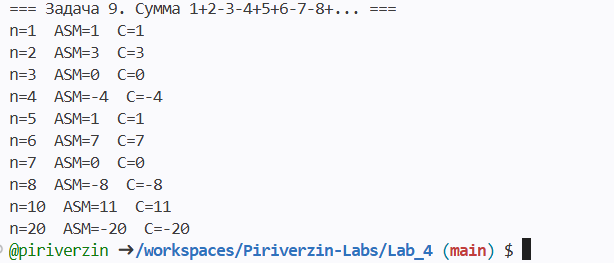

**Вывод:** результаты ASM и C полностью совпадают.

---
## Задача 7. Цифры через ноль

### Исходный код (task7.asm)

```asm
format ELF executable 3
entry start
segment readable executable
start:
    mov eax, 3
    mov ebx, 0
    mov ecx, inbuf
    mov edx, 16
    int 0x80
    mov esi, inbuf
    call parse_int
    mov [n], eax
    mov eax, [n]
    mov edi, digits + 15
    mov byte [edi], 0
    dec edi
    mov ebx, 10
    ...
```

### Исходный код на C (task7.c)

```c
#include <stdio.h>
int main(void) {
    int n;
    scanf("%d", &n);
    char buf[32];
    int len = snprintf(buf, sizeof(buf), "%d", n);
    for (int i = 0; i < len; i++) {
        putchar(buf[i]);
        putchar('0');
    }
    putchar('\n');
    return 0;
}
```

In [ ]:
!fasm task7.asm task7
!chmod +x task7
!gcc -Os -s -o task7_c task7.c
for n in [5, 12, 123, 1234, 987]:
    a = !echo {n} | ./task7
    c = !echo {n} | ./task7_c
    print(f'n={n}  ASM={a[0]}  C={c[0]}')

### Результат работы
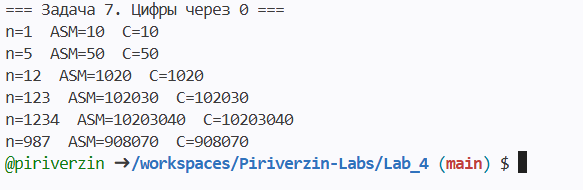

---
## Задача 5. Числа, не делящиеся на 11 и 5

### Исходный код (task5.asm)

```asm
format ELF executable 3
entry start
segment readable executable
start:
    mov eax, 3
    mov ebx, 0
    mov ecx, inbuf
    mov edx, 16
    int 0x80
    mov esi, inbuf
    call parse_int
    mov [n], eax
    xor ebx, ebx
    mov ecx, 1
.loop:
    cmp ecx, [n]
    jg .done
    mov eax, ecx
    xor edx, edx
    mov esi, 11
    div esi
    test edx, edx
    jz .skip
    mov eax, ecx
    xor edx, edx
    mov esi, 5
    div esi
    test edx, edx
    jz .skip
    inc ebx
.skip:
    inc ecx
    jmp .loop
.done:
    mov eax, ebx
    call print_num
    ...
```

### Исходный код на C (task5.c)

```c
#include <stdio.h>
int main(void) {
    int n;
    scanf("%d", &n);
    int count = 0;
    for (int k = 1; k <= n; k++) {
        if (k % 11 != 0 && k % 5 != 0) count++;
    }
    printf("%d\n", count);
    return 0;
}
```

In [ ]:
!fasm task5.asm task5
!chmod +x task5
!gcc -Os -s -o task5_c task5.c
for n in [5, 10, 11, 20, 55, 100]:
    a = !echo {n} | ./task5
    c = !echo {n} | ./task5_c
    print(f'n={n}  ASM={a[0]}  C={c[0]}')

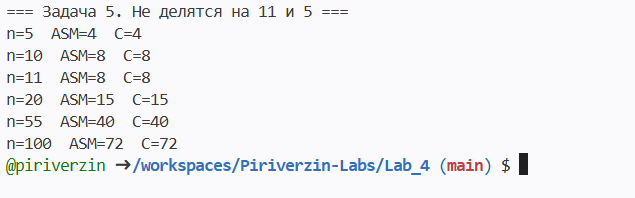

---
## Вывод по лабораторной работе

1. Реализованы три программы на ассемблере (FASM): сумма `1+2-3-4+...`, цифры через ноль, подсчёт чисел не делящихся на 11 и 5.
2. Для каждой программы реализована аналогичная на C.
3. Результаты обеих реализаций **совпадают** на всех тестовых наборах.
4. Ввод в ассемблерных программах реализован через системный вызов `read`.